# 06 — XGBoost Station-Level 1-Day-Ahead Forecast

**Sections**
1. Setup
2. Load data
3. Feature engineering
4. Train / test split
5. Train XGBoost
6. Evaluate
7. Visualize predictions

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from dotenv import load_dotenv
from divvy_demand.infra.s3_client import S3Client

load_dotenv('../../.env')
s3 = S3Client(env='prod')


def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, np.nan, y_true))) * 100

def smape(y_true, y_pred):
    return np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred))) * 100

def mase(y_true, y_pred, y_train):
    naive_mae = np.mean(np.abs(np.diff(y_train)))
    return mean_absolute_error(y_true, y_pred) / naive_mae

## 2. Load data

In [2]:
station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])
station = station[station['start_station_name'] != 'Outside of Dock']

weather = s3.read_processed('weather/historical')
weather['date'] = pd.to_datetime(weather['date'])

weather_fcst = s3.read_processed('weather/forecast')
weather_fcst['date'] = pd.to_datetime(weather_fcst['date'])

print('Station:', station.shape)
print('Weather (hist):', weather.shape)
print('Weather (fcst):', weather_fcst.shape)
station.head()

Station: (1402616, 7)
Weather (hist): (2251, 5)
Weather (fcst): (2251, 5)


,date,start_station_name,start_station_id,total_rides,ebike_rides,member_rides,casual_rides
0,2020-01-01,63rd St Beach,101,2,0,2,0
1,2020-01-01,900 W Harrison St,109,1,0,1,0
2,2020-01-01,Aberdeen St & Jackson Blvd,21,2,0,2,0
3,2020-01-01,Aberdeen St & Monroe St,80,7,0,7,0
4,2020-01-01,Aberdeen St & Randolph St,621,3,0,3,0


## 3. Feature engineering

In [3]:
# Filter to stations active on >95% of days
n_days = station['date'].nunique()
min_active_days = int(0.95 * n_days)
active_stations = (
    station.groupby('start_station_name')['date']
    .nunique()
    .loc[lambda s: s > min_active_days]
    .index
)
df = station[station['start_station_name'].isin(active_stations)].copy()
print(f'Stations kept (>{min_active_days}/{n_days} days): {len(active_stations)}')
print(f'Rows: {len(df)}')

Stations kept (>2136/2249 days): 311
Rows: 689248


In [4]:
# Merge weather
df = df.merge(
    weather[['date', 'temp_min_c', 'rain_sum_mm', 'snowfall_sum_cm', 'wind_speed_max_kmh']],
    on='date', how='left'
)
df = df.sort_values(['start_station_name', 'date']).reset_index(drop=True)

# --- Calendar features ---
df['day']          = df['date'].dt.day
df['month']        = df['date'].dt.month
df['year']         = df['date'].dt.year
df['weekday']      = df['date'].dt.weekday
DOW_COLS           = [f'dow_{d}' for d in range(7)]
for d in range(7):
    df[f'dow_{d}'] = (df['weekday'] == d).astype(int)
df['week_of_year'] = df['date'].dt.isocalendar().week.astype(int)
df['is_weekend']   = df['weekday'].isin([5, 6]).astype(int)

# --- Raw count lag features (lag-safe, no leakage) ---
grp = df.groupby('start_station_name')['total_rides']
for lag in [1, 2, 7, 30, 60, 90, 365]:
    df[f'y_lag{lag}'] = grp.shift(lag)

# --- Rolling mean & volatility on raw counts (shift(1) before rolling) ---
df['rolling_avg_7']  = grp.transform(lambda x: x.shift(1).rolling(7,  min_periods=1).mean())
df['rolling_avg_30'] = grp.transform(lambda x: x.shift(1).rolling(30, min_periods=1).mean())
df['rolling_std_7']  = grp.transform(lambda x: x.shift(1).rolling(7,  min_periods=2).std())
df['rolling_std_30'] = grp.transform(lambda x: x.shift(1).rolling(30, min_periods=2).std())

# --- Yearly rolling proportion features (lag-1 safe) ---
total_safe = df['total_rides'].replace(0, np.nan)
df['ebike_prop']  = df['ebike_rides']  / total_safe
df['member_prop'] = df['member_rides'] / total_safe
for col in ['ebike_prop', 'member_prop']:
    df[f'{col}_roll365_lag1'] = (
        df.groupby('start_station_name')[col]
        .transform(lambda x: x.shift(1).rolling(365, min_periods=30).mean())
    )

# --- Station dummy variables ---
station_dummies = pd.get_dummies(df['start_station_name'], prefix='stn', drop_first=False)
df = pd.concat([df, station_dummies], axis=1)
STATION_COLS = station_dummies.columns.tolist()

df = df.dropna(subset=['y_lag1', 'y_lag7', 'y_lag365'])
print(f'Rows after lag drop: {len(df)}')
df.head()


Rows after lag drop: 575733


,date,start_station_name,start_station_id,total_rides,ebike_rides,member_rides,casual_rides,temp_min_c,rain_sum_mm,snowfall_sum_cm,...,stn_Wilton Ave & Belmont Ave,stn_Wilton Ave & Diversey Pkwy,stn_Winchester Ave & Elston Ave,stn_Winthrop Ave & Lawrence Ave,stn_Wolcott (Ravenswood) Ave & Montrose Ave,stn_Wolcott Ave & Polk St,stn_Wood St & Augusta Blvd,stn_Wood St & Hubbard St,stn_Wood St & Milwaukee Ave,stn_Woodlawn Ave & 55th St
365,2021-01-07,900 W Harrison St,13028,5,1,5,0,-0.2,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
366,2021-01-08,900 W Harrison St,13028,2,1,2,0,-0.2,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
367,2021-01-10,900 W Harrison St,13028,3,1,1,2,-3.5,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
368,2021-01-11,900 W Harrison St,13028,5,2,2,3,-5.2,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
369,2021-01-12,900 W Harrison St,13028,6,1,5,1,-3.3,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False


In [5]:
df.head().T

,365,366,367,368,369
date,2021-01-07 00:00:00,2021-01-08 00:00:00,2021-01-10 00:00:00,2021-01-11 00:00:00,2021-01-12 00:00:00
start_station_name,900 W Harrison St,900 W Harrison St,900 W Harrison St,900 W Harrison St,900 W Harrison St
start_station_id,13028,13028,13028,13028,13028
total_rides,5,2,3,5,6
ebike_rides,1,1,1,2,1
...,...,...,...,...,...
stn_Wolcott Ave & Polk St,False,False,False,False,False
stn_Wood St & Augusta Blvd,False,False,False,False,False
stn_Wood St & Hubbard St,False,False,False,False,False
stn_Wood St & Milwaukee Ave,False,False,False,False,False


## 4. Train / test split

In [6]:
max_date = df['date'].max()
test_start = max_date - pd.DateOffset(years=1) + pd.Timedelta(days=1)
val_start  = max_date - pd.DateOffset(years=2) + pd.Timedelta(days=1)

train = df[df['date'] <  val_start].copy()
val   = df[(df['date'] >= val_start) & (df['date'] < test_start)].copy()
test  = df[df['date'] >= test_start].copy()

print(f'Train: {train["date"].min().date()} -> {train["date"].max().date()}  ({len(train):,} rows)')
print(f'Val:   {val["date"].min().date()}   -> {val["date"].max().date()}    ({len(val):,} rows)')
print(f'Test:  {test["date"].min().date()}  -> {test["date"].max().date()}   ({len(test):,} rows)')

# Swap actual weather for forecast weather in test set
WEATHER_COLS = ['temp_min_c', 'rain_sum_mm', 'snowfall_sum_cm', 'wind_speed_max_kmh']
test = test.drop(columns=WEATHER_COLS).merge(
    weather_fcst[['date'] + WEATHER_COLS], on='date', how='left'
)
print(f'Test weather NaN after forecast merge: {test[WEATHER_COLS].isna().sum().to_dict()}')

DOW_COLS = [f'dow_{d}' for d in range(7)]
FEATURES = [
    'day', 'month', 'week_of_year', 'is_weekend',
    'temp_min_c', 'rain_sum_mm', 'snowfall_sum_cm', 'wind_speed_max_kmh',
    'y_lag1', 'y_lag2', 'y_lag7', 'y_lag30', 'y_lag60', 'y_lag90', 'y_lag365',
    'rolling_avg_7', 'rolling_avg_30', 'rolling_std_7', 'rolling_std_30',
    'ebike_prop_roll365_lag1', 'member_prop_roll365_lag1',
] + DOW_COLS + STATION_COLS
TARGET = 'total_rides'


X_train, y_train = train[FEATURES], train[TARGET]
X_val,   y_val   = val[FEATURES],   val[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]


Train: 2021-01-02 -> 2024-02-28  (351,285 rows)
Val:   2024-02-29   -> 2025-02-28    (112,905 rows)
Test:  2025-03-01  -> 2026-02-28   (111,543 rows)
Test weather NaN after forecast merge: {'temp_min_c': 0, 'rain_sum_mm': 0, 'snowfall_sum_cm': 0, 'wind_speed_max_kmh': 0}


## 5. Train XGBoost

In [7]:
## 5. Train XGBoost — Andrew's hyperparameters
model = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.1,
    max_depth=10,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    reg_lambda=5,
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=30,
    eval_metric="rmse",
)
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=50,
)
print(f"Best iteration: {model.best_iteration}")


[0]	validation_0-rmse:31.02525	validation_1-rmse:28.21091
[50]	validation_0-rmse:8.85740	validation_1-rmse:11.27575
[100]	validation_0-rmse:8.02731	validation_1-rmse:11.21269
[150]	validation_0-rmse:7.58165	validation_1-rmse:11.18660
[200]	validation_0-rmse:7.22844	validation_1-rmse:11.16642
[250]	validation_0-rmse:6.94734	validation_1-rmse:11.15547
[300]	validation_0-rmse:6.70288	validation_1-rmse:11.15351
[350]	validation_0-rmse:6.49205	validation_1-rmse:11.14230
[400]	validation_0-rmse:6.30851	validation_1-rmse:11.13555
[450]	validation_0-rmse:6.13208	validation_1-rmse:11.12806
[500]	validation_0-rmse:5.98197	validation_1-rmse:11.12265
[550]	validation_0-rmse:5.82936	validation_1-rmse:11.11764
[600]	validation_0-rmse:5.68432	validation_1-rmse:11.11264
[650]	validation_0-rmse:5.54069	validation_1-rmse:11.11104
[669]	validation_0-rmse:5.49506	validation_1-rmse:11.11137
Best iteration: 639


In [8]:
import os, json as _json

MODEL_DIR  = '../models'
MODEL_PATH = os.path.join(MODEL_DIR, 'xgb_station_1day.json')

model.save_model(MODEL_PATH)

# Save metadata alongside the model
meta = {
    'features': FEATURES,
    'target': TARGET,
    'val_start':  str(val['date'].min().date()),
    'test_start': str(test['date'].min().date()),
    'best_iteration': model.best_iteration,
}
with open(os.path.join(MODEL_DIR, 'xgb_station_1day_meta.json'), 'w') as f:
    _json.dump(meta, f, indent=2)

print(f'Model saved to {MODEL_PATH}')
print(f'Features: {len(FEATURES)}  |  Best iteration: {model.best_iteration}')


Model saved to ../models/xgb_station_1day.json
Features: 339  |  Best iteration: 639


## 6. Evaluate

In [9]:
y_pred_val  = model.predict(X_val)
y_pred_test = model.predict(X_test)

def metrics_dict(y_true, y_pred, y_tr):
    return {
        'RMSE':  mean_squared_error(y_true, y_pred) ** 0.5,
        'MAE':   mean_absolute_error(y_true, y_pred),
        'MAPE':  mape(y_true.values, y_pred),
        'sMAPE': smape(y_true.values, y_pred),
        'MASE':  mase(y_true.values, y_pred, y_tr.values),
        'R2':    r2_score(y_true, y_pred),
    }

metrics_overall = pd.DataFrame({
    'Val':  metrics_dict(y_val,  y_pred_val,  y_train),
    'Test': metrics_dict(y_test, y_pred_test, y_train),
}).T.round(4)
metrics_overall


,RMSE,MAE,MAPE,sMAPE,MASE,R2
Val,11.1108,7.1215,41.9327,29.3170,0.6531,0.8687
Test,10.5769,6.7781,49.5507,31.4433,0.6217,0.8578


In [10]:
# Per-station metrics
val_eval  = val[['date', 'start_station_name', 'total_rides']].copy()
val_eval['pred']  = np.maximum(y_pred_val, 0)
test_eval = test[['date', 'start_station_name', 'total_rides']].copy()
test_eval['pred'] = np.maximum(y_pred_test, 0)

per_station = (
    test_eval.groupby('start_station_name')
    .apply(lambda g: pd.Series({
        'r2':    r2_score(g['total_rides'], g['pred']),
        'rmse':  mean_squared_error(g['total_rides'], g['pred']) ** 0.5,
        'mae':   mean_absolute_error(g['total_rides'], g['pred']),
        'smape': smape(g['total_rides'].values, g['pred'].values),
    }))
    .sort_values('r2', ascending=False)
)
per_station.head(10)


,r2,rmse,mae,smape
start_station_name,,,,
Wells St & Huron St,0.851942,15.277651,11.451447,20.908224
Broadway & Cornelia Ave,0.845023,14.044822,10.277976,25.319483
Sheridan Rd & Irving Park Rd,0.834442,8.904380,6.892836,22.990996
Clark St & Elm St,0.829013,20.066065,14.244884,24.305981
Dearborn Pkwy & Delaware Pl,0.826724,13.906300,10.667148,23.796427
Michigan Ave & Oak St,0.822898,38.671130,26.773149,41.825530
Kingsbury St & Erie St,0.822481,11.574248,9.198191,20.984350
Ellis Ave & 60th St,0.820621,13.954909,10.500176,30.960645
Wells St & Concord Ln,0.816813,19.299376,14.784141,23.516766


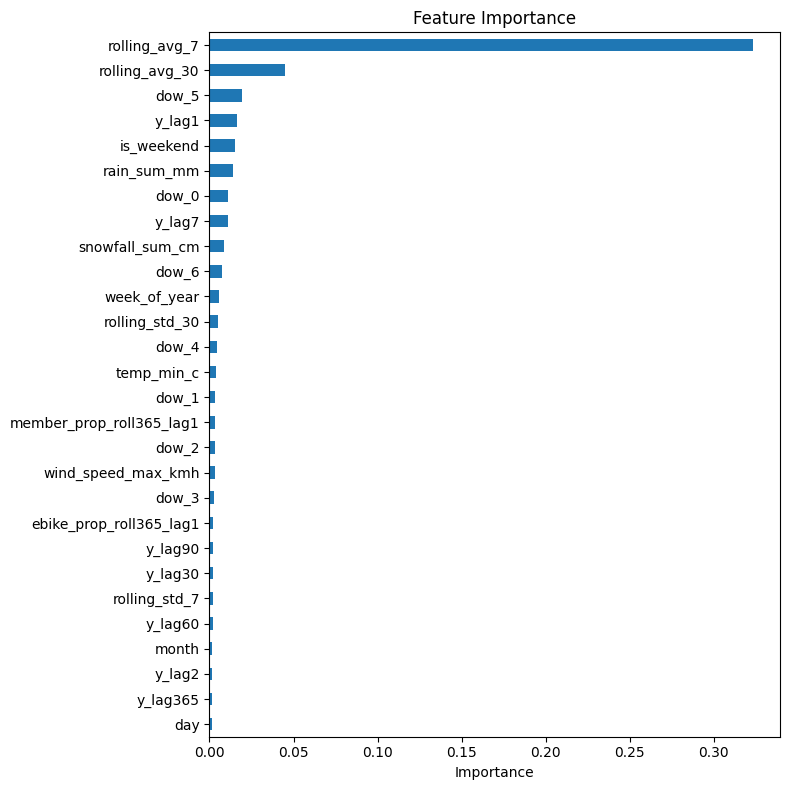

In [11]:
# Feature importance (excluding any station one-hot if added later)
fi = pd.Series(model.feature_importances_, index=FEATURES)
fi = fi[~fi.index.str.startswith('stn_')].sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(8, 8))
fi.plot.barh(ax=ax)
ax.set_title('Feature Importance')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

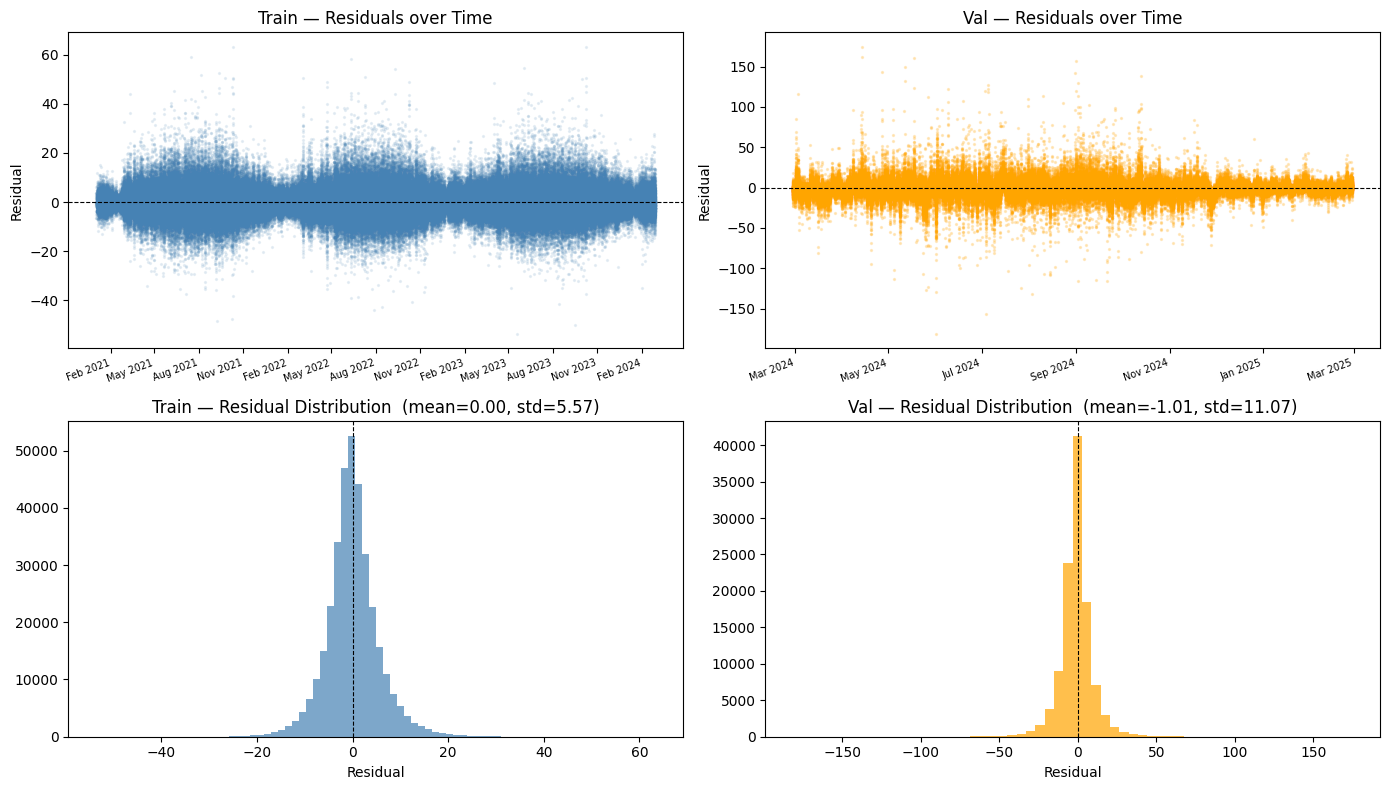

In [12]:
y_pred_train = model.predict(X_train)

train_resid = y_train.values - y_pred_train
val_resid   = y_val.values   - y_pred_val

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# --- Train residuals over time ---
axes[0, 0].scatter(train['date'], train_resid, alpha=0.1, s=2, color='steelblue')
axes[0, 0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0, 0].set_title('Train — Residuals over Time')
axes[0, 0].set_ylabel('Residual')
axes[0, 0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[0, 0].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(axes[0, 0].xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)

# --- Val residuals over time ---
axes[0, 1].scatter(val['date'], val_resid, alpha=0.2, s=2, color='orange')
axes[0, 1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0, 1].set_title('Val — Residuals over Time')
axes[0, 1].set_ylabel('Residual')
axes[0, 1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[0, 1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.setp(axes[0, 1].xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)

# --- Train residual distribution ---
axes[1, 0].hist(train_resid, bins=80, color='steelblue', alpha=0.7, edgecolor='none')
axes[1, 0].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[1, 0].set_title(f'Train — Residual Distribution  (mean={train_resid.mean():.2f}, std={train_resid.std():.2f})')
axes[1, 0].set_xlabel('Residual')

# --- Val residual distribution ---
axes[1, 1].hist(val_resid, bins=60, color='orange', alpha=0.7, edgecolor='none')
axes[1, 1].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[1, 1].set_title(f'Val — Residual Distribution  (mean={val_resid.mean():.2f}, std={val_resid.std():.2f})')
axes[1, 1].set_xlabel('Residual')

plt.tight_layout()
plt.show()


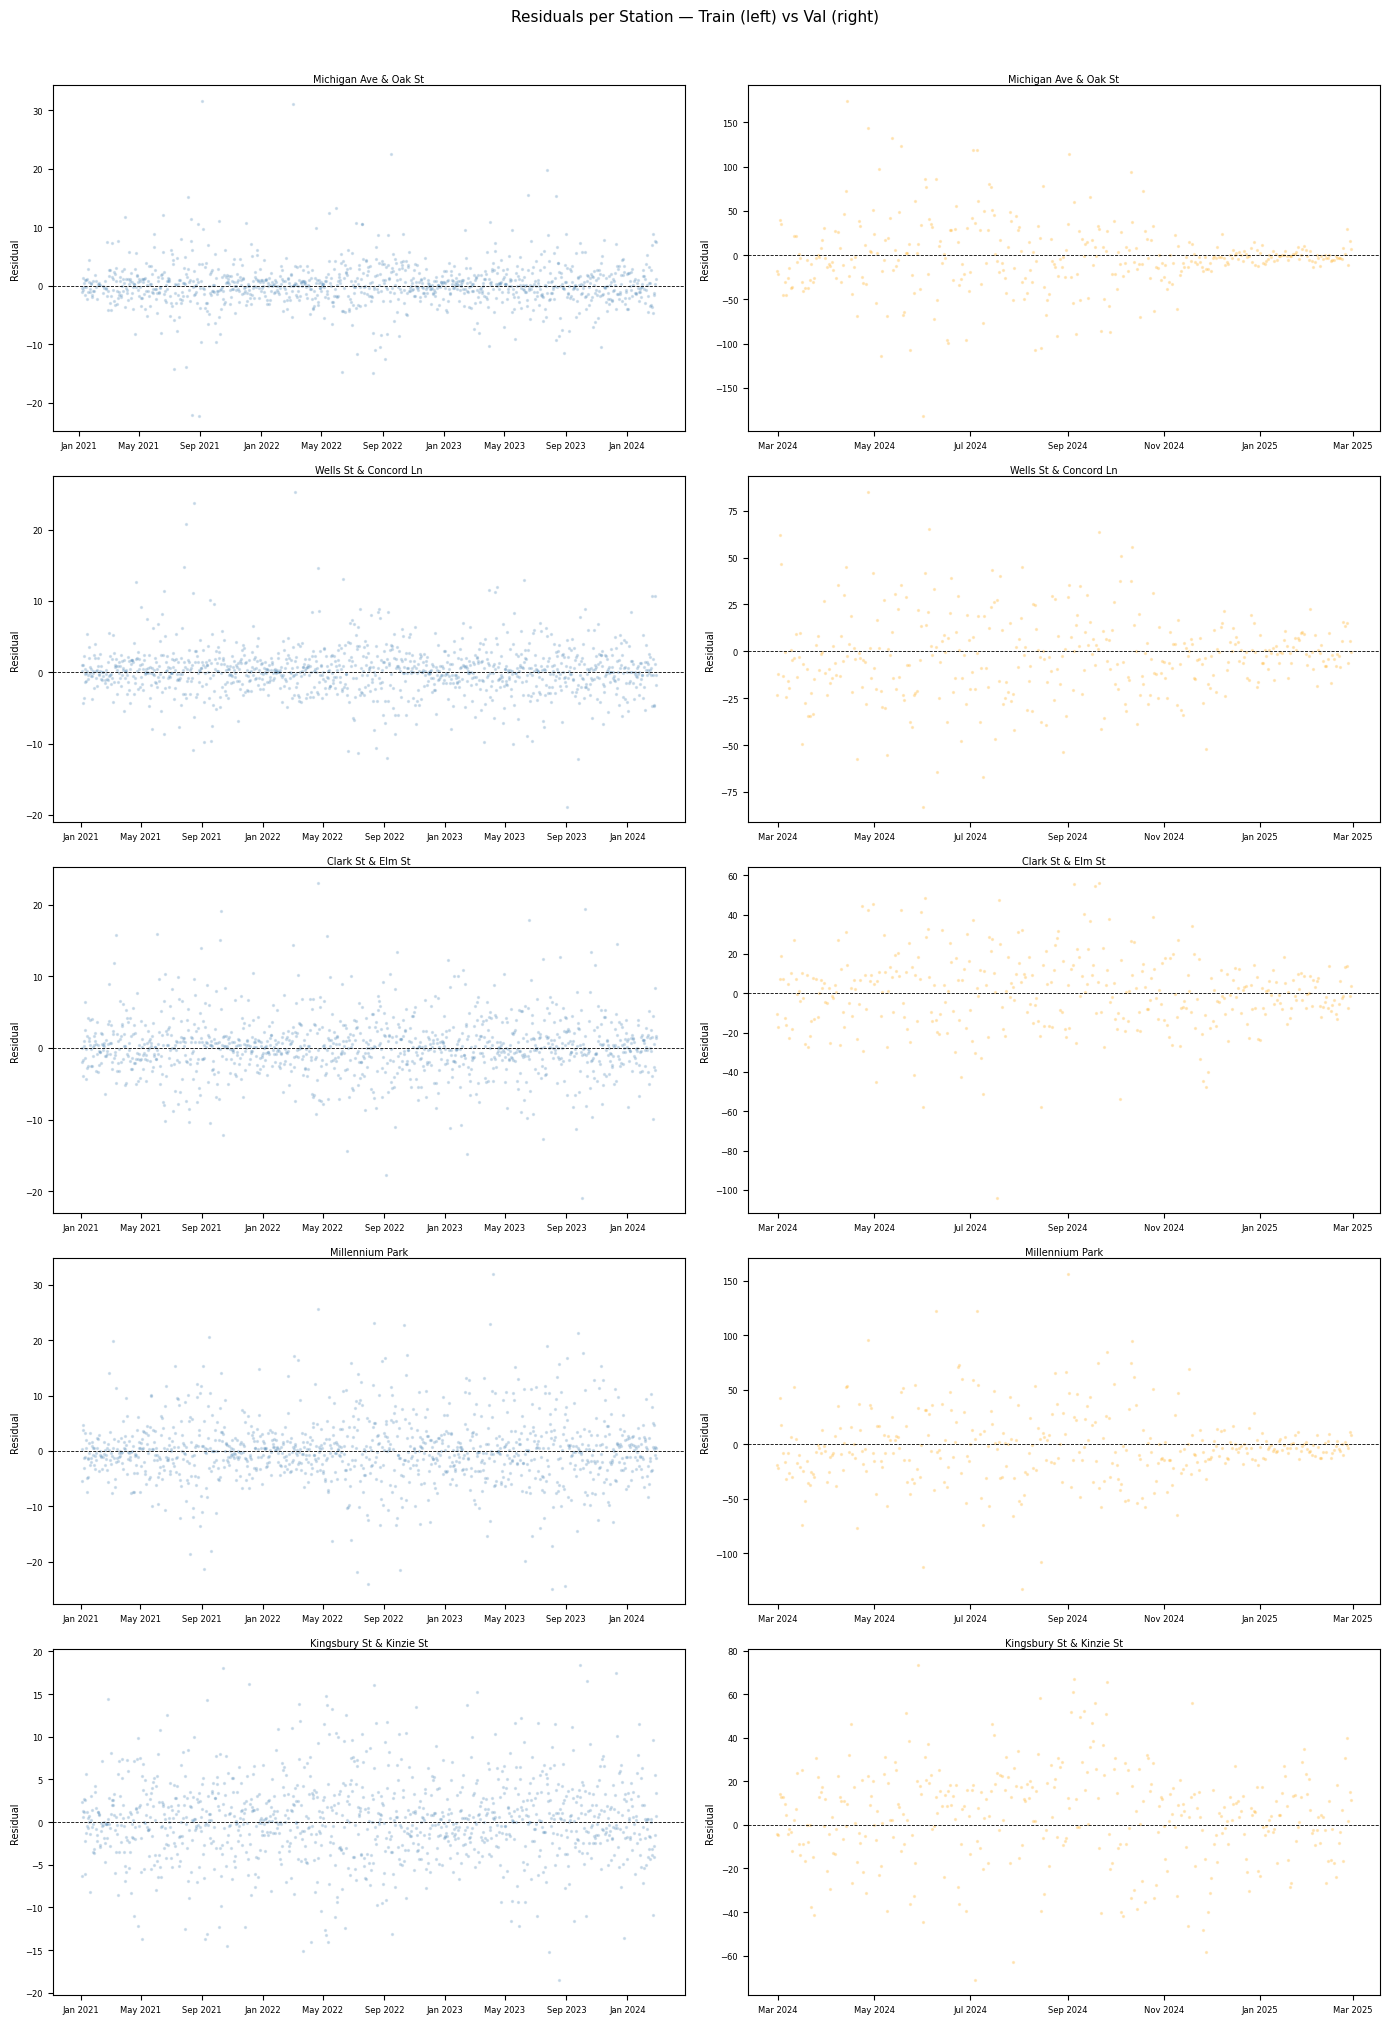

In [13]:
# Residuals per station for top5
top5 = (
    train.groupby("start_station_name")["total_rides"]
    .sum().sort_values(ascending=False).head(5).index.tolist()
)

train_eval = train[['date', 'start_station_name', 'total_rides']].copy()
train_eval['pred']  = np.maximum(y_pred_train, 0)
train_eval['resid'] = train_eval['total_rides'] - train_eval['pred']

val_eval['resid'] = val_eval['total_rides'] - val_eval['pred']

fig, axes = plt.subplots(5, 2, figsize=(14, 20), sharex=False)
fig.suptitle('Residuals per Station — Train (left) vs Val (right)', fontsize=11, y=1.01)

for row, name in enumerate(top5):
    tr = train_eval[train_eval['start_station_name'] == name].sort_values('date')
    vl = val_eval[val_eval['start_station_name'] == name].sort_values('date')

    for ax, data, color in [(axes[row,0], tr, 'steelblue'), (axes[row,1], vl, 'orange')]:
        ax.scatter(data['date'], data['resid'], alpha=0.2, s=2, color=color)
        ax.axhline(0, color='black', linewidth=0.6, linestyle='--')
        ax.set_title(name[:40], fontsize=7, pad=2)
        ax.set_ylabel('Residual', fontsize=7)
        ax.tick_params(axis='both', labelsize=6)
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.tight_layout()
plt.show()


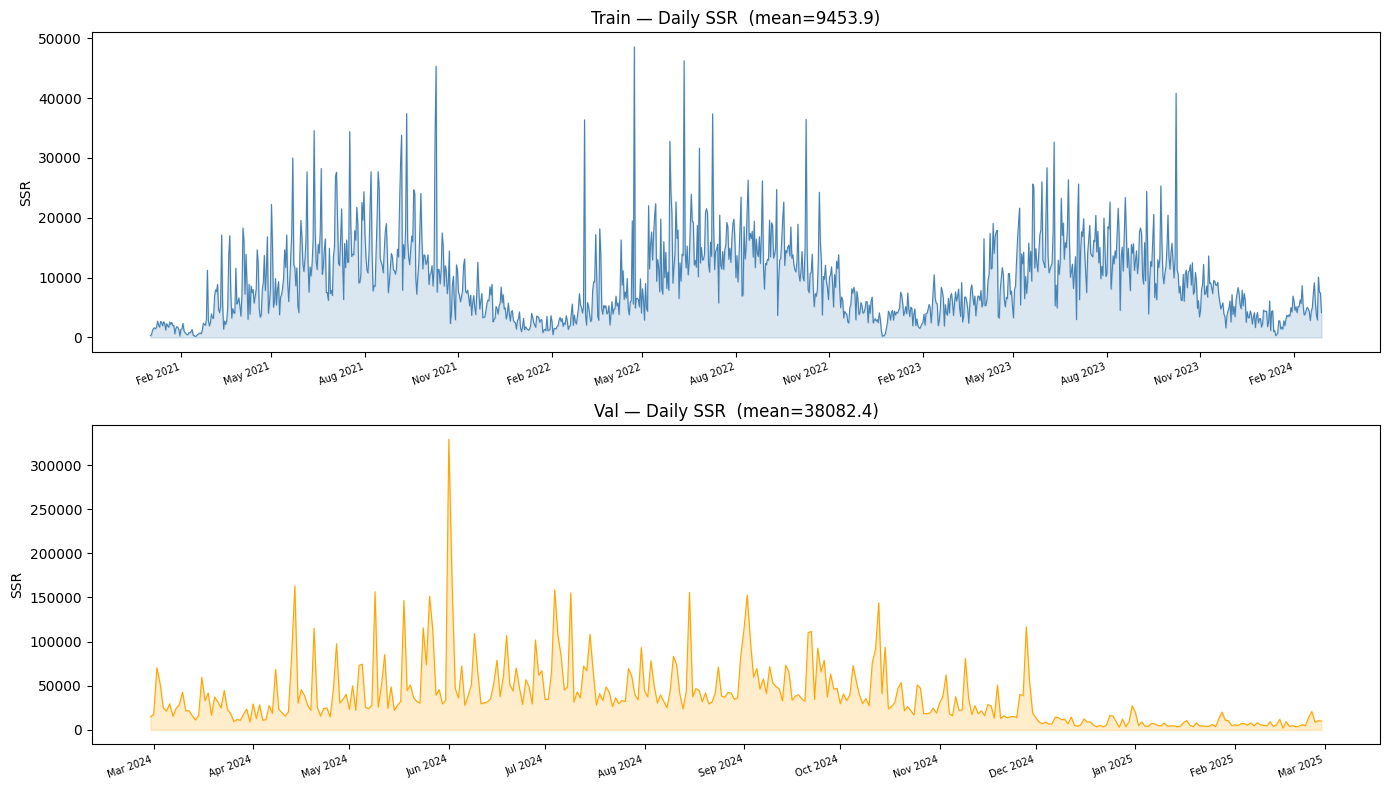

In [14]:
# Sum of squared residuals per day (across all stations)
train_eval['resid2'] = train_eval['resid'] ** 2
val_eval['resid2']   = val_eval['resid'] ** 2

ssr_train = train_eval.groupby('date')['resid2'].sum().rename('SSR')
ssr_val   = val_eval.groupby('date')['resid2'].sum().rename('SSR')

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

axes[0].plot(ssr_train.index, ssr_train.values, linewidth=0.8, color='steelblue')
axes[0].fill_between(ssr_train.index, ssr_train.values, alpha=0.2, color='steelblue')
axes[0].set_title(f'Train — Daily SSR  (mean={ssr_train.mean():.1f})')
axes[0].set_ylabel('SSR')
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)

axes[1].plot(ssr_val.index, ssr_val.values, linewidth=0.8, color='orange')
axes[1].fill_between(ssr_val.index, ssr_val.values, alpha=0.2, color='orange')
axes[1].set_title(f'Val — Daily SSR  (mean={ssr_val.mean():.1f})')
axes[1].set_ylabel('SSR')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=1))
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)

plt.tight_layout()
plt.show()


## 7. Visualize predictions

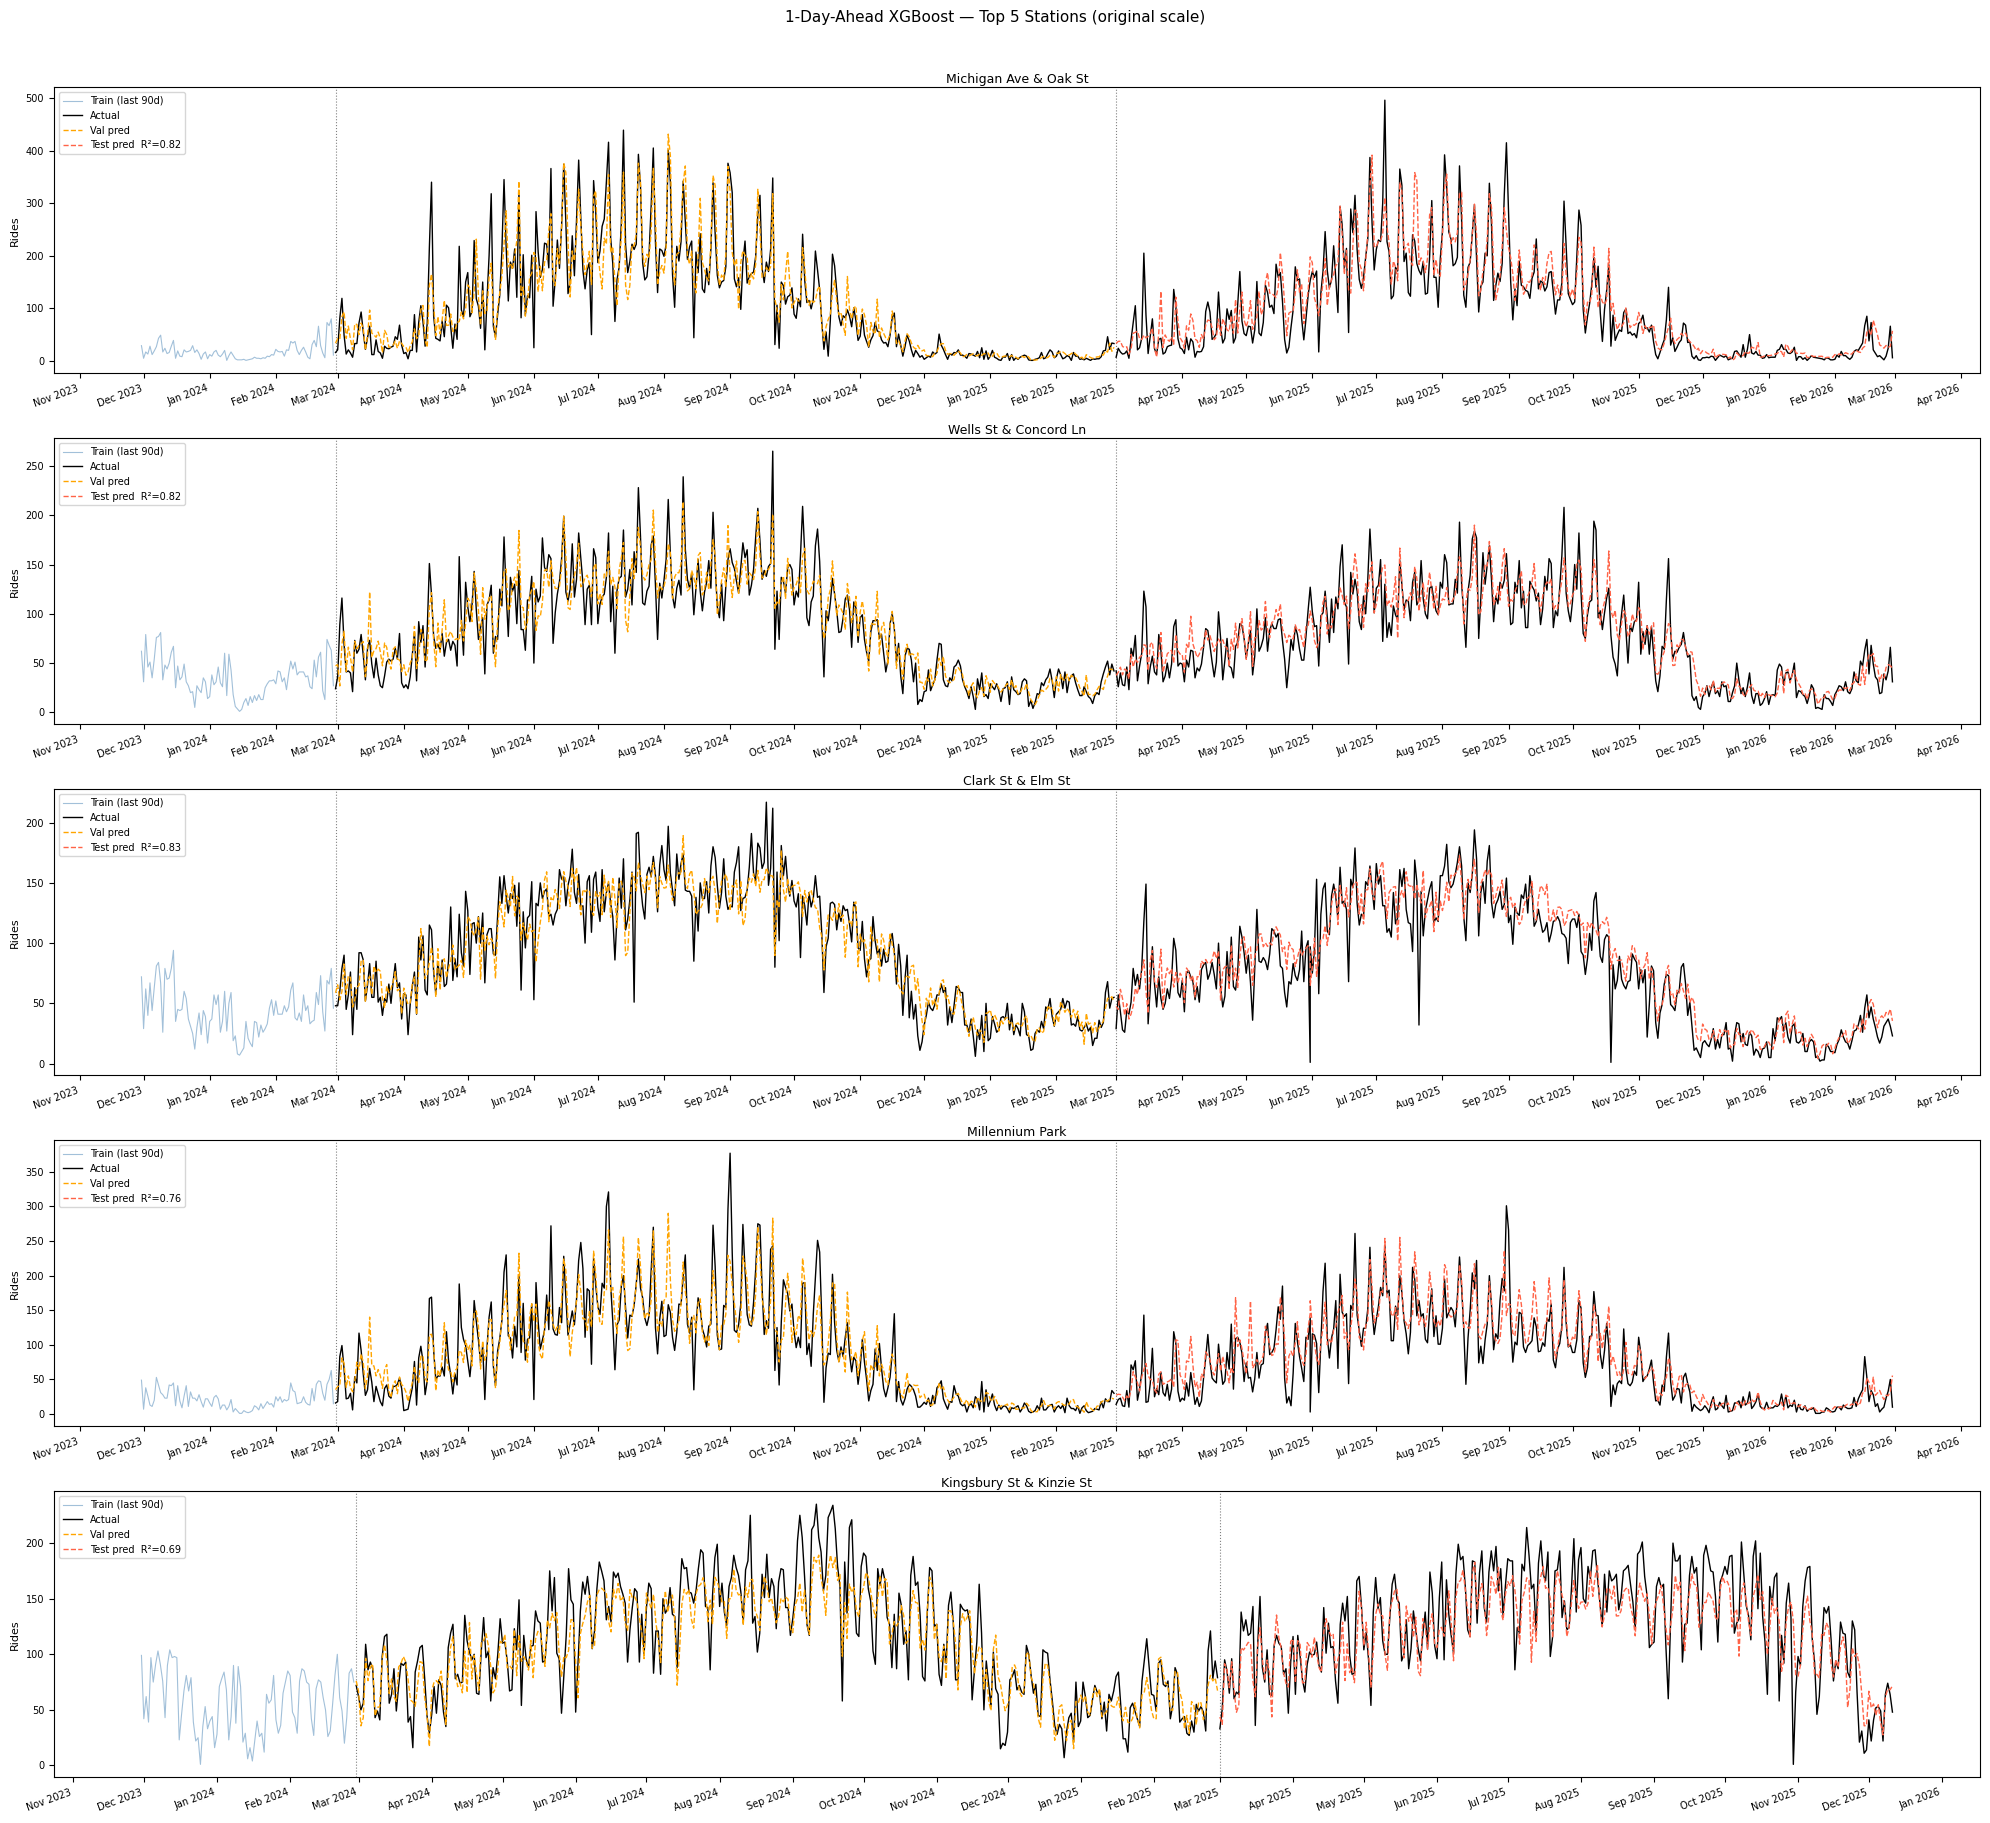

In [15]:
# Top 5 stations by total rides in train
top5 = (
    train.groupby('start_station_name')['total_rides']
    .sum().sort_values(ascending=False).head(5).index.tolist()
)

CONTEXT_DAYS = 90
fig, axes = plt.subplots(5, 1, figsize=(20, 18), sharex=False)

for ax, name in zip(axes, top5):
    tr = train[train['start_station_name'] == name]
    tr_ctx = tr[tr['date'] >= tr['date'].max() - pd.Timedelta(days=CONTEXT_DAYS)]
    vl = val_eval[val_eval['start_station_name'] == name].sort_values('date')
    te = test_eval[test_eval['start_station_name'] == name].sort_values('date')
    r2_s = per_station.loc[name, 'r2']

    ax.plot(tr_ctx['date'], tr_ctx['total_rides'], color='steelblue', alpha=0.5, linewidth=0.8, label='Train (last 90d)')
    ax.axvline(vl['date'].min(), color='grey', linestyle=':', linewidth=0.8)
    ax.axvline(te['date'].min(), color='grey', linestyle=':', linewidth=0.8)
    ax.plot(vl['date'], vl['total_rides'], color='black',  linewidth=1, label='Actual')
    ax.plot(vl['date'], vl['pred'],        color='orange', linestyle='--', linewidth=1, label='Val pred')
    ax.plot(te['date'], te['total_rides'], color='black',  linewidth=1)
    ax.plot(te['date'], te['pred'],        color='tomato', linestyle='--', linewidth=1, label=f'Test pred  R²={r2_s:.2f}')
    ax.set_title(name, fontsize=9, pad=3)
    ax.set_ylabel('Rides', fontsize=8)
    ax.legend(fontsize=7, loc='upper left')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)
    ax.tick_params(axis='y', labelsize=7)

fig.suptitle('1-Day-Ahead XGBoost — Top 5 Stations (original scale)', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()


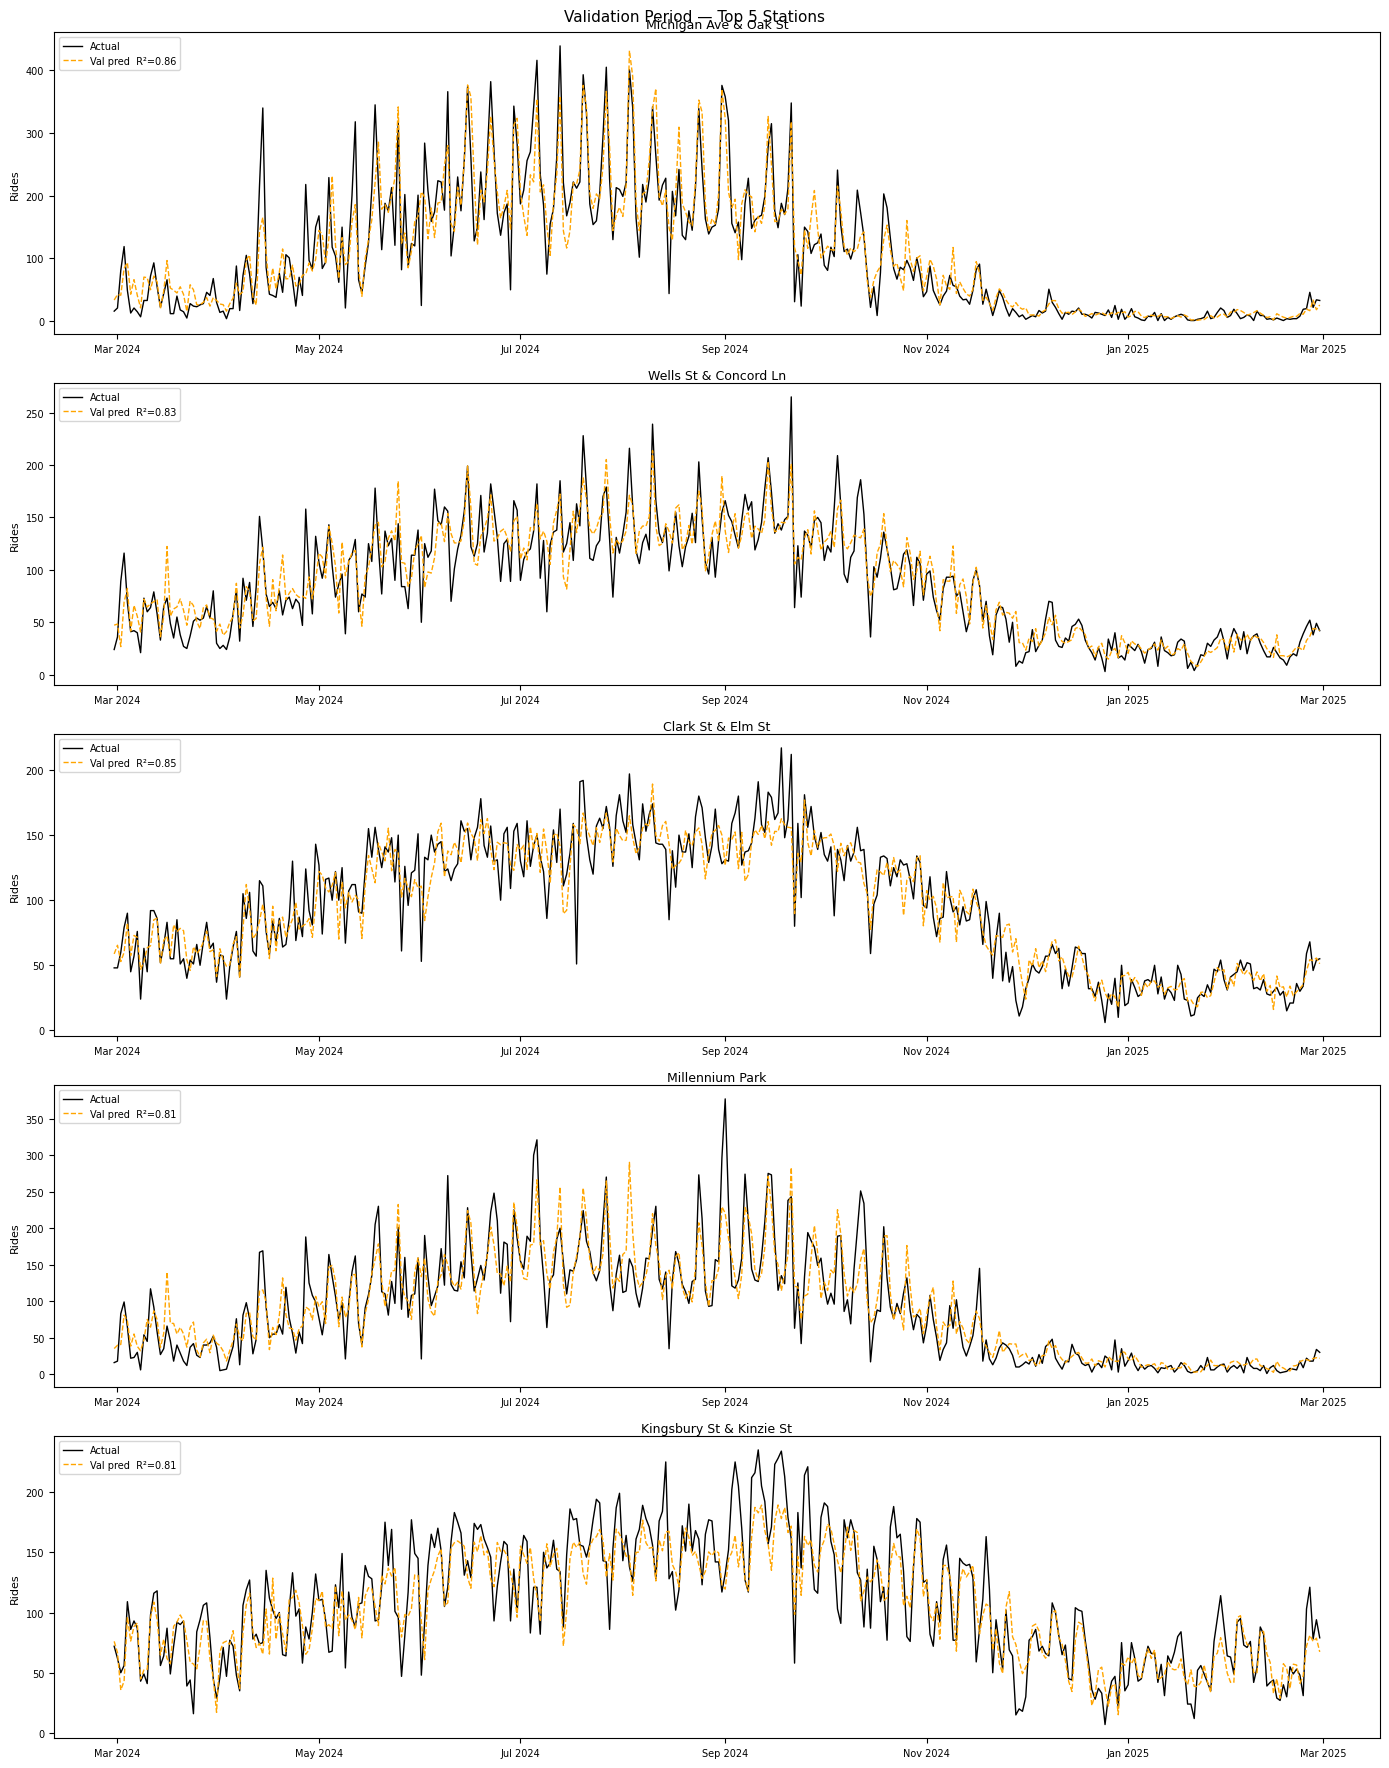

In [16]:
# Validation period only
fig, axes = plt.subplots(5, 1, figsize=(14, 18), sharex=False)

for ax, name in zip(axes, top5):
    vl = val_eval[val_eval['start_station_name'] == name].sort_values('date')
    r2_v = r2_score(vl['total_rides'], vl['pred'])

    ax.plot(vl['date'], vl['total_rides'], color='black',  linewidth=1,   label='Actual')
    ax.plot(vl['date'], vl['pred'],        color='orange', linestyle='--', linewidth=1, label=f'Val pred  R²={r2_v:.2f}')
    ax.set_title(name, fontsize=9, pad=3)
    ax.set_ylabel('Rides', fontsize=8)
    ax.legend(fontsize=7, loc='upper left')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.tick_params(axis='both', labelsize=7)

fig.suptitle('Validation Period — Top 5 Stations', fontsize=11)
plt.tight_layout()
plt.show()
